# Run vs Pass models

In [68]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)

### Import data

In [ ]:
TRAIN_SEASONS = (2015, 2022)
TEST_SEASONS  = (2023, 2025)
INCLUDE_PLAYOFFS = True

core = pd.read_csv("data_core_raw.csv", low_memory=False, 
                   dtype={"game_id": str, "posteam": str, "defteam": str, "td_team": str})
scores = pd.read_csv("data_scores.csv", dtype={"game_id": str, "team": str})

if not INCLUDE_PLAYOFFS:
    core = core[core.season_type == "REG"]

CATS = ["<=0"] + [str(i) for i in range(1, 11)] + ["11-14", "15-19", "20-29", "30+", "TD", "TO"]
LOWER = np.array([-np.inf] + list(range(1, 11)) + [11, 15, 20, 30, -np.inf, -np.inf])
UPPER = np.array([0] + list(range(1, 11)) + [14, 19, 29, 99, np.nan, np.nan])

s = scores[["game_id", "team", "off_score", "def_score", "first_game", "early_game"]]
data = (core[(core["pass"] == 1) | (core["rush"] == 1)]
     .sort_values(["game_id", "drive", "play_id"]))
data["prev_gain"] = (data.groupby(["game_id", "drive"])["yards_gained"].shift(1) > 0).astype(int)
data = data[data.down.isin([1, 2, 3]) & (data.qtr <= 4) & data.play_type.isin(["pass", "run"]) & (data.qb_kneel == 0) & (data.qb_spike == 0)]
data = (data.merge(s.rename(columns={"team": "posteam", "first_game": "off_first_game", "early_game": "off_early_game"})
              .drop(columns="def_score"), on=["game_id", "posteam"], how="left")
      .merge(s.rename(columns={"team": "defteam", "first_game": "def_first_game", "early_game": "def_early_game"})
              .drop(columns="off_score"), on=["game_id", "defteam"], how="left"))
data = data.dropna(subset=["off_score", "def_score"]) 

bins = [-np.inf, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 19, 29, np.inf]
out = pd.cut(data.yards_gained, bins, labels=CATS[:15]).astype(str)
out = np.where((data.touchdown == 1) & (data.td_team == data.posteam), "TD", out)
out = np.where((data.interception == 1) | (data.fumble_lost == 1), "TO", out)
data["outcome"] = pd.Categorical(out, categories=CATS)
data["y"] = data.outcome.cat.codes
data["model"] = np.where(data["pass"] == 1, "pass", "run")
data["sample"] = np.select([data.season.between(*TRAIN_SEASONS), data.season.between(*TEST_SEASONS)], ["train", "test"], "unused")

print(pd.crosstab(data.model, data["sample"], margins=True).to_string())

### Create train/test datasets

In [5]:
ZONES = ["01-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "81-90", "91-99"]
YTG = ["1", "2", "3", "4-5", "6-7", "8-10", "11+"]
REF = {"zone": "41-50", "down": "1", "ytg": "8-10"}
NUMERIC = ["prev_gain", "off_score", "def_score", "off_first_game", "off_early_game", "def_first_game", "def_early_game"]

cat = lambda v, cats: pd.Series(pd.Categorical(v, categories=cats), index=data.index)
zone = cat(pd.cut(data.yardline_100, [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels=ZONES), ZONES)
ytg = cat(pd.cut(data.ydstogo.clip(upper=15), [0, 1, 2, 3, 5, 7, 10, 15], labels=YTG), YTG)
down = cat(data.down.astype(int).astype(str), ["1", "2", "3"])
X = pd.concat([
    data["model"],
    data["sample"],
    pd.get_dummies(zone, prefix="zone").drop(columns=f"zone_{REF['zone']}"),
    pd.get_dummies(down, prefix="down").drop(columns=f"down_{REF['down']}"),
    pd.get_dummies(ytg, prefix="ytg").drop(columns=f"ytg_{REF['ytg']}"),
    data[NUMERIC]], axis=1)
X = sm.add_constant(X, has_constant="add")

y_train_pass = data.y[(data.model == "pass") & (data["sample"] == "train")]
y_train_run = data.y[(data.model == "run") & (data["sample"] == "train")]

y_test_pass = data.y[(data.model == "pass") & (data["sample"] == "test")]
y_test_run = data.y[(data.model == "run") & (data["sample"] == "test")]

X_train_pass = X[(X.model == "pass") & (X["sample"] == "train")].drop(["model", "sample"], axis=1).astype(float)
X_train_run = X[(X.model == "run") & (X["sample"] == "train")].drop(["model", "sample"], axis=1).astype(float)

X_test_pass = X[(X.model == "pass") & (X["sample"] == "test")].drop(["model", "sample"], axis=1).astype(float)
X_test_run = X[(X.model == "run") & (X["sample"] == "test")].drop(["model", "sample"], axis=1).astype(float)

FEATURES = list(X.columns)

### Train the models

In [11]:
models, typical = {}, {}

# Pass model
t0 = time.time()
model_pass = sm.MNLogit(y_train_pass, X_train_pass).fit(method="lbfgs", maxiter=1000, disp=False)
models["pass"] = model_pass
typical["pass"] = data[(data.model == "pass") 
    & (data["sample"] == "train")].groupby("outcome", observed=False)["yards_gained"].mean().reindex(CATS).fillna(0).values
print(f"pass: n = {len(X_train_pass):,}  converged = {model_pass.mle_retvals['converged']}  "
      f"pseudo-R² = {model_pass.prsquared:.4f}  log-lik = {model_pass.llf:,.0f}  ({time.time() - t0:.0f} s)")

# Run model
t0 = time.time()
model_run = sm.MNLogit(y_train_run, X_train_run).fit(method="lbfgs", maxiter=1000, disp=False)
models["run"] = model_run
typical["run"] = data[(data.model == "run") 
    & (data["sample"] == "train")].groupby("outcome", observed=False)["yards_gained"].mean().reindex(CATS).fillna(0).values
print(f"run: n = {len(X_train_run):,}  converged = {model_run.mle_retvals['converged']}  "
      f"pseudo-R² = {model_run.prsquared:.4f}  log-lik = {model_run.llf:,.0f}  ({time.time() - t0:.0f} s)")

pass: n = 163,064  converged = True  pseudo-R² = 0.0369  log-lik = -364,795  (183 s)
run: n = 102,632  converged = True  pseudo-R² = 0.0369  log-lik = -246,253  (105 s)


### Test-set evaluation

In [12]:
def softmax_probs(X, B):
    eta = np.column_stack([np.zeros(len(X)), X @ B])
    eta -= eta.max(axis=1, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(axis=1, keepdims=True)

def goal_line_fix(P, yardline):
    P = P.copy()
    P[LOWER[None, :] >= np.asarray(yardline)[:, None]] = 0
    return P / P.sum(axis=1, keepdims=True)

def summarize(P, ytg, yardline, typ):
    ytg, yl = np.asarray(ytg, float)[:, None], np.asarray(yardline, float)[:, None]
    tv = np.broadcast_to(typ, P.shape).copy()
    tv[:, CATS.index("TD")] = yl[:, 0]; tv[:, CATS.index("TO")] = 0
    tv = np.minimum(tv, yl)
    lo, hi = LOWER[None, :], UPPER[None, :]
    reach = np.where(lo >= ytg, 1.0, np.where((hi >= ytg) & (lo < ytg) & np.isfinite(lo), (hi - ytg + 1) / (hi - lo + 1), 0.0))
    reach[:, CATS.index("TD")] = 1; reach[:, CATS.index("TO")] = 0; reach[:, 0] = 0
    return {"exp_yards": (P * tv).sum(1), "p_first_down": (P * reach).sum(1),
            "p_td": P[:, CATS.index("TD")], "p_to": P[:, CATS.index("TO")], "p_le0": P[:, 0]}

In [82]:
warnings.filterwarnings("ignore")
test_pred, rows = {}, []

# Pass model evaluation
data_test_pass = data[(data.model == "pass") & (data["sample"] == "test")]
X = X_test_pass
B = models["pass"].params.values
P = goal_line_fix(softmax_probs(X, B), data_test_pass.yardline_100.values)

P, sm_ = [P, summarize(P, data_test_pass.ydstogo.values, data_test_pass.yardline_100.values, typical["pass"])]

test_pred["pass"] = [X_test_pass, P, summarize(P, data_test_pass.ydstogo.values, 
                                               data_test_pass.yardline_100.values, typical["pass"])]
y = y_test_pass
freq = y_train_pass.value_counts(normalize=True).reindex(range(len(CATS)), fill_value=0).values
Pb = goal_line_fix(np.tile(freq, (len(data_test_pass), 1)), data_test_pass.yardline_100.values)
ll = -np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)))
llb = -np.mean(np.log(np.clip(Pb[np.arange(len(y)), y], 1e-12, 1)))
fd_obs = (((data_test_pass.yards_gained >= data_test_pass.ydstogo) & (data_test_pass.outcome != "TO")) 
          | (data_test_pass.outcome == "TD")).astype(int)
rows.append({"model": "pass", "test plays": len(data_test_pass), "log-loss (model)": ll, "log-loss (baseline)": llb,
             "improvement": 1 - ll / llb,
             "mean yards: predicted": sm_["exp_yards"].mean(), 
             "mean yards: observed": data_test_pass.yards_gained.where(data_test_pass.outcome != "TO", 0).mean(),
             "P(1st down): predicted": sm_["p_first_down"].mean(), "P(1st down): observed": fd_obs.mean()})
data_test_pass.loc[:,"fd_obs"] = fd_obs.values

# Run model evaluation
data_test_run = data[(data.model == "run") & (data["sample"] == "test")]
X = X_test_run
B = models["run"].params.values
P = goal_line_fix(softmax_probs(X, B), data_test_run.yardline_100.values)

P, sm_ = [P, summarize(P, data_test_run.ydstogo.values, data_test_run.yardline_100.values, typical["run"])]

test_pred["run"] = [X_test_run, P, summarize(P, data_test_run.ydstogo.values, 
                                               data_test_run.yardline_100.values, typical["run"])]
y = y_test_run
freq = y_train_run.value_counts(normalize=True).reindex(range(len(CATS)), fill_value=0).values
Pb = goal_line_fix(np.tile(freq, (len(data_test_run), 1)), data_test_run.yardline_100.values)
ll = -np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)))
llb = -np.mean(np.log(np.clip(Pb[np.arange(len(y)), y], 1e-12, 1)))
fd_obs = (((data_test_run.yards_gained >= data_test_run.ydstogo) & (data_test_run.outcome != "TO")) 
          | (data_test_run.outcome == "TD")).astype(int)
rows.append({"model": "run", "test plays": len(data_test_run), "log-loss (model)": ll, "log-loss (baseline)": llb,
             "improvement": 1 - ll / llb,
             "mean yards: predicted": sm_["exp_yards"].mean(), 
             "mean yards: observed": data_test_run.yards_gained.where(data_test_run.outcome != "TO", 0).mean(),
             "P(1st down): predicted": sm_["p_first_down"].mean(), "P(1st down): observed": fd_obs.mean()})
data_test_run.loc[:,"fd_obs"] = fd_obs.values

evaluation = pd.DataFrame(rows).set_index("model")
evaluation.style.format({"test plays": "{:,}", "log-loss (model)": "{:.4f}", "log-loss (baseline)": "{:.4f}",
                         "improvement": "{:.1%}", "mean yards: predicted": "{:.2f}", "mean yards: observed": "{:.2f}",
                         "P(1st down): predicted": "{:.1%}", "P(1st down): observed": "{:.1%}"})



,test plays,log-loss (model),log-loss (baseline),improvement,mean yards: predicted,mean yards: observed,P(1st down): predicted,P(1st down): observed
model,,,,,,,,
pass,"61,511",2.2525,2.2995,2.0%,6.29,6.23,32.6%,31.5%
run,"40,219",2.3918,2.4327,1.7%,4.20,4.26,23.4%,23.4%


### Visualize results

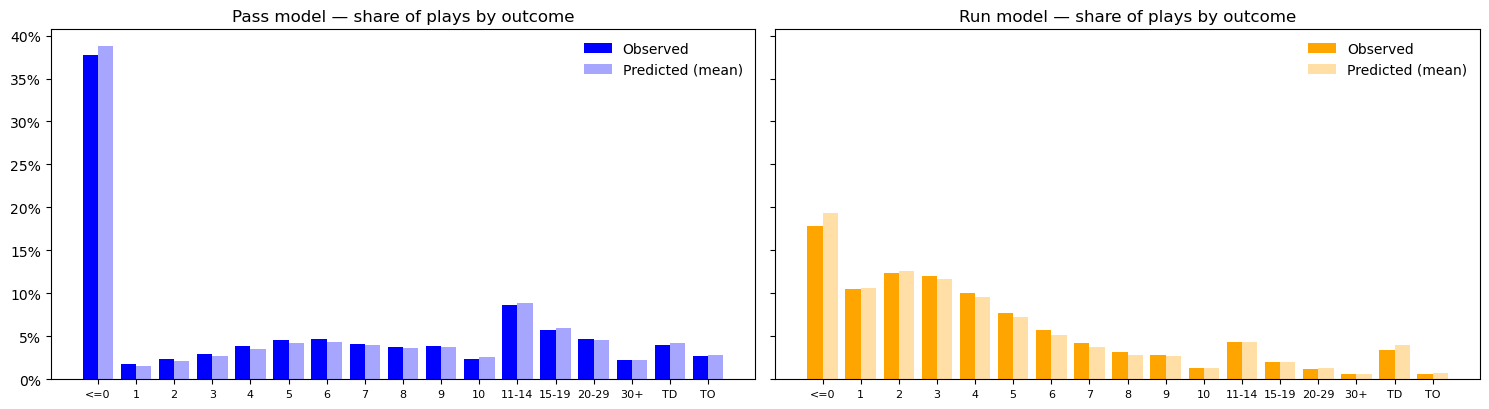

In [106]:
# Predicted vs observed outcome distributions (test seasons)
COLOR = {"pass": "blue", "run": "orange"}
data_plot = {"pass": data_test_pass, "run": data_test_run}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, ["pass", "run"]):
    te, P, _ = test_pred[name]
    obs = data_plot[name].outcome.value_counts(normalize=True).reindex(CATS).values
    x = np.arange(len(CATS))
    ax.bar(x - 0.2, obs, 0.4, color=COLOR[name], label="Observed")
    ax.bar(x + 0.2, P.mean(0), 0.4, color=COLOR[name], alpha=0.35, label="Predicted (mean)")
    ax.set_xticks(x, CATS, rotation=0, fontsize=8); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"{name.title()} model — share of plays by outcome"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

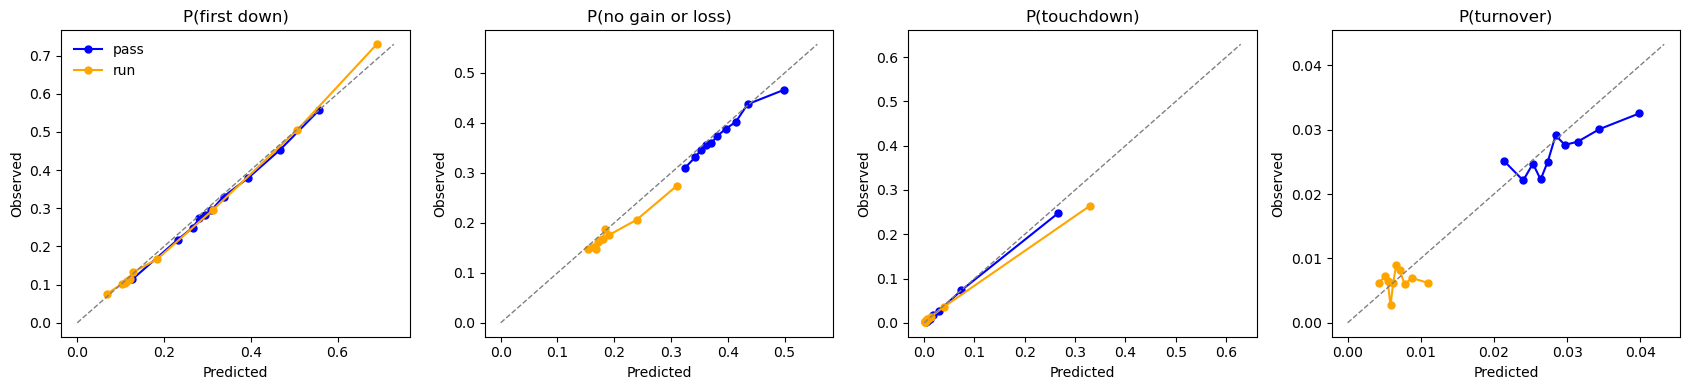

In [109]:
# Calibration — do predicted probabilities match outcomes

def calib(ax, pred, obs, color, label, nbins=10):
    q = pd.qcut(pred, nbins, duplicates="drop")
    g = pd.DataFrame({"p": pred, "o": obs}).groupby(q, observed=True).mean()
    ax.plot(g.p, g.o, "o-", color=color, ms=5, lw=1.5, label=label)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
targets = [("p_first_down", lambda te: te.fd_obs, "P(first down)"),
           ("p_le0", lambda te: (te.outcome == "<=0").astype(int), "P(no gain or loss)"),
           ("p_td", lambda te: (te.outcome == "TD").astype(int), "P(touchdown)"),
           ("p_to", lambda te: (te.outcome == "TO").astype(int), "P(turnover)")]
for ax, (key, obsf, title) in zip(axes, targets):
    hi = 0
    for name in ["pass", "run"]:
        te, P, sm_ = test_pred[name]
        calib(ax, sm_[key], obsf(data_plot[name]).values, COLOR[name], name)
        hi = max(hi, np.quantile(sm_[key], 0.99))
    ax.plot([0, hi], [0, hi], color="gray", lw=1, ls="--")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

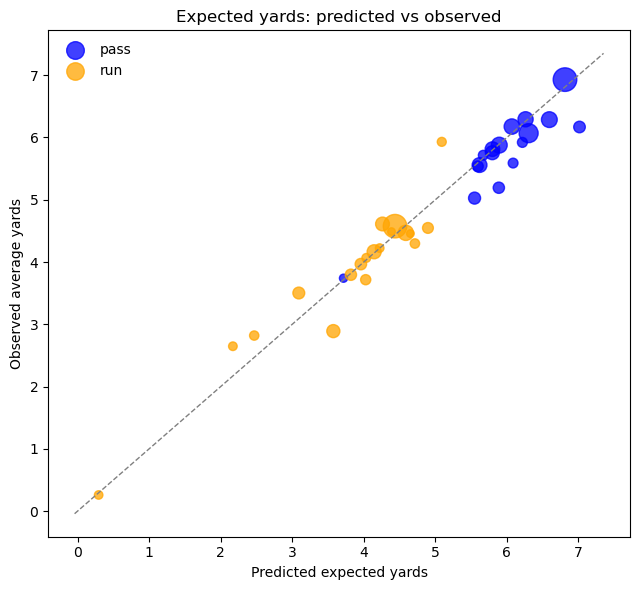

In [112]:
# Expected yards by situation

fig, ax = plt.subplots(figsize=(6.5, 6))
for name in ["pass", "run"]:
    te, P, sm_ = test_pred[name]
    g = (data_plot[name].assign(pred=sm_["exp_yards"], obs=data_plot[name].yards_gained.where(data_plot[name].outcome != "TO", 0),
                   ytg_grp=pd.cut(data_plot[name].ydstogo.clip(upper=15), [0, 1, 2, 3, 5, 7, 10, 15], labels=YTG))
         .groupby(["down", "ytg_grp"], observed=True).agg(pred=("pred", "mean"), obs=("obs", "mean"), n=("obs", "size")))
    g = g[g.n >= 200]
    ax.scatter(g.pred, g.obs, s=np.sqrt(g.n) * 2, color=COLOR[name], alpha=0.75, label=name)
lim = [ax.get_xlim()[0], ax.get_xlim()[1]]
ax.plot(lim, lim, color="gray", ls="--", lw=1)
ax.set_xlabel("Predicted expected yards"); ax.set_ylabel("Observed average yards")
ax.set_title("Expected yards: predicted vs observed"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. Example: one situation (point estimates)

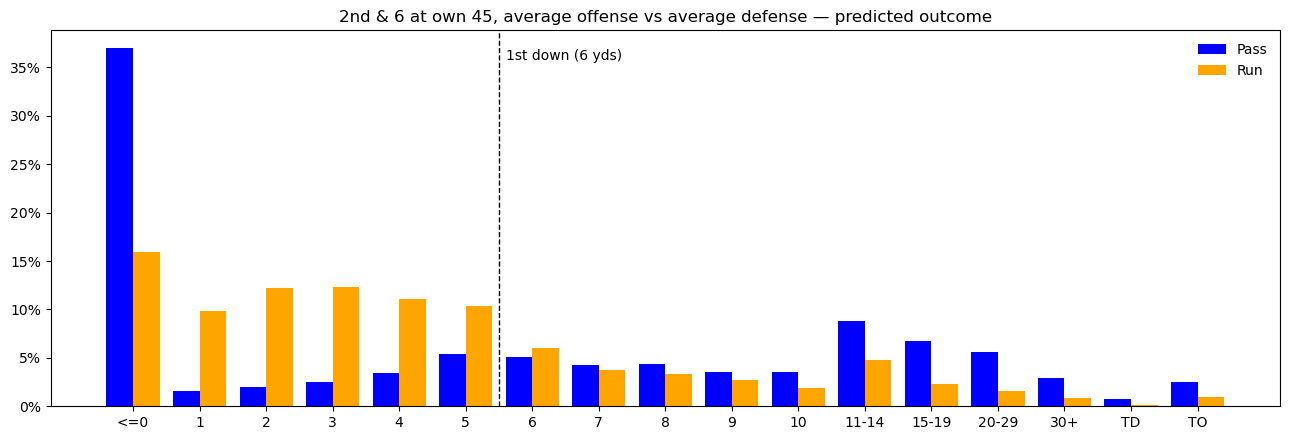

,Pass,Run
exp_yards,6.873,4.565
p_first_down,0.457,0.273
p_td,0.008,0.002
p_to,0.025,0.009
p_le0,0.370,0.160


In [145]:
def create_dataset(df):
    cat = lambda v, cats: pd.Series(pd.Categorical(v, categories=cats), index=df.index)
    zone = cat(pd.cut(df.yardline_100, [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels=ZONES), ZONES)
    ytg = cat(pd.cut(df.ydstogo.clip(upper=15), [0, 1, 2, 3, 5, 7, 10, 15], labels=YTG), YTG)
    down = cat(df.down.astype(int).astype(str), ["1", "2", "3"])
    X = pd.concat([
        pd.get_dummies(zone, prefix="zone").drop(columns=f"zone_{REF['zone']}"),
        pd.get_dummies(down, prefix="down").drop(columns=f"down_{REF['down']}"),
        pd.get_dummies(ytg, prefix="ytg").drop(columns=f"ytg_{REF['ytg']}"),
        df[NUMERIC]], axis=1).astype(float)
    return sm.add_constant(X, has_constant="add")
    
def situation(down=2, ytg=6, yardline_100=55, prev_gain=1, off_score=0.0, def_score=0.0):
    return pd.DataFrame([{"down": down, "ydstogo": ytg, "yardline_100": yardline_100, "prev_gain": prev_gain,
                          "off_score": off_score, "def_score": def_score, "off_first_game": 0, "off_early_game": 0,
                          "def_first_game": 0, "def_early_game": 0}])

sit = situation(down=2, ytg=6, yardline_100=55)
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(CATS)); summary = {}

for k, name in enumerate(["pass", "run"]):
    B = models[name].params.values
    P = goal_line_fix(softmax_probs(create_dataset(sit), B), sit.yardline_100.values)
    smry = summarize(P, sit.ydstogo, sit.yardline_100, typical[name])
    ax.bar(x + (k - 0.5) * 0.4, P[0], 0.4, color=COLOR[name], label=name.title())
    summary[name.title()] = {key: round(float(v[0]), 3) for key, v in smry.items()}

ax.axvline(CATS.index("6") - 0.5, color="k", ls="--", lw=1)
ax.text(CATS.index("6") - 0.4, ax.get_ylim()[1] * 0.92, "1st down (6 yds)")
ax.set_xticks(x, CATS); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("2nd & 6 at own 45, average offense vs average defense — predicted outcome")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
pd.DataFrame(summary)